# EXERKINEMAP: Exerkine–Metabolite SMILES-to-SMILES Molecular Generation

**Research notebook | reproducible, source-aware, scaffold-aware**

This notebook builds a denoising SMILES-to-SMILES model for proposing *analogous molecular structures* conditioned on exercise-responsive metabolites. It uses RDKit for chemical standardization and validation, a character-level encoder–decoder Transformer in PyTorch, and evaluation designed to expose invalid structures, memorization, and scaffold leakage.

## Important terminology and data provenance

- **Exerkine** is commonly used for an exercise-responsive signaling factor; the term can include proteins/peptides and, in broader usage, exercise-responsive metabolites.
- **ZINC is primarily a purchasable-compound database, not a curated metabolomics or exerkine database.** Treat ZINC SMILES as a *chemical-space prior* only. Do not label ZINC molecules as exercise-responsive metabolites without independent evidence.
- The model below is a **denoising SMILES generator**, not a validated predictor of exercise response, bioactivity, safety, or clinical benefit. Generated structures are hypotheses, not findings.
- Use empirical exercise/metabolomics labels from a traceable source (for example, a published MoTrPAC analysis or MetaboLights study) and preserve study, species, tissue, intervention, and identifier metadata. Do not merge human and animal labels without explicit species/ortholog/compound mapping.
- A genuine paired translation model needs defensible input–target molecular pairs. This notebook instead learns to reconstruct a clean SMILES from a corrupted version and then samples analogues from a supplied seed structure. It does **not** invent biological input–target pairs.

**Outputs:** standardized input table, model checkpoint, generated candidate table with provenance, and evaluation metrics.

## 1. Reproducibility and configuration

Run in a clean Python 3.10–3.12 environment. GPU is optional; CPU training can be slow. The notebook records package versions, random seeds, and the configuration used. For a publication, pin the environment in a lockfile and report the exact data release / download date.

In [1]:
from pathlib import Path
import os, sys, json, random, hashlib, platform, warnings
from datetime import datetime, timezone

SEED = 20261018
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

import numpy as np
import pandas as pd

np.random.seed(SEED)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "raw" / "exerkine_metabolites"
OUT_DIR = ROOT / "results" / "smiles_generation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Expected inputs (CSV):
#   exercise_metabolites.csv: smiles, compound_name, source, species, study_id,
#       exercise_response (optional), response_direction (optional)
#   zinc_smiles.csv: smiles (and optional zinc_id)
#
# Set these paths to your local files. No external data are silently fabricated.
EXERCISE_CSV = DATA_DIR / "exercise_metabolites.csv"
ZINC_CSV = DATA_DIR / "zinc_smiles.csv"

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("UTC run time:", datetime.now(timezone.utc).isoformat())
print("Working directory:", ROOT)
print("Output directory:", OUT_DIR.resolve())

Python: 3.14.8
Platform: macOS-27.0.1-arm64-arm-64bit-Mach-O
UTC run time: 2026-10-19T06:35:34.676741+00:00
Working directory: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks
Output directory: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/results/smiles_generation


## 2. Install / import chemistry and ML dependencies

Install only if needed. For reproducibility, use a dedicated environment rather than modifying a shared research environment.

In [3]:
# If needed, uncomment and run in the notebook:
#%pip install rdkit pandas numpy scikit-learn matplotlib torch

In [4]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.warning")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("RDKit:", __import__("rdkit").__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0
RDKit: 2026.09.1
Device: cpu


In [12]:
import pandas as pd
from pathlib import Path

rows = [
# input_label, normalized_name, smiles, type/status, notes, source
("12,13-diHOME", "12,13-DiHOME (12,13-dihydroxy-9Z-octadecenoic acid)", r"CCCCCC(C(C/C=C\CCCCCCCC(=O)O)O)O", "single_compound; provisional structure", "PubChem CID 10236635; hydroxyl stereochemistry is not fully specified in this SMILES.", "https://pubchem.ncbi.nlm.nih.gov/compound/10236635"),
("AICAR", "AICAR / acadesine vs ZMP", "C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N", "ambiguous_identity", "AICAR commonly means acadesine (AICAr, riboside) or its phosphorylated intracellular metabolite ZMP. Choose the intended form before assigning one SMILES.", "https://pubchem.ncbi.nlm.nih.gov/#query=AICAR"),
("BAIBA", "beta-aminoisobutyric acid (BAIBA)", "CC(CN)C(=O)O", "single_compound; stereochemistry unspecified", "BAIBA has stereoisomers; this SMILES does not specify stereochemistry.", "https://pubchem.ncbi.nlm.nih.gov/#query=beta-aminoisobutyric%20acid"),
("2-OHB", "2-hydroxybutyric acid / 2-hydroxybutyrate", "CCC(C(=O)O)O", "single_compound; stereochemistry unspecified", "Also called alpha-hydroxybutyrate; stereochemistry can be biologically relevant.", "https://pubchem.ncbi.nlm.nih.gov/#query=2-hydroxybutyric%20acid"),
("3-OH", "3-hydroxybutyric acid / 3-hydroxybutyrate", "CC(CC(=O)O)O", "tentative_identity", "Interpreted as 3-hydroxybutyrate (beta-hydroxybutyrate); confirm this is what '3-OH' means.", "https://pubchem.ncbi.nlm.nih.gov/#query=3-hydroxybutyric%20acid"),
("Glycine", "Glycine", "NCC(=O)O", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=glycine"),
("Alanine", "Alanine", "CC(N)C(=O)O", "single_compound; stereochemistry unspecified", "Common biological L-alanine is stereospecific; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=alanine"),
("Valine", "Valine", "CC(C)C(N)C(=O)O", "single_compound; stereochemistry unspecified", "Common biological L-valine is stereospecific; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=valine"),
("Leucine", "Leucine", "CC(C)CC(N)C(=O)O", "single_compound; stereochemistry unspecified", "Common biological L-leucine is stereospecific; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=leucine"),
("Isoleucine", "Isoleucine", "CCC(C)C(N)C(=O)O", "single_compound; stereochemistry unspecified", "Common biological L-isoleucine has two stereocenters; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=isoleucine"),
("Methionine", "Methionine", "CSCCC(N)C(=O)O", "single_compound; stereochemistry unspecified", "Common biological L-methionine is stereospecific; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=methionine"),
("Proline", "Proline", "O=C(O)C1CCCN1", "single_compound; stereochemistry unspecified", "Common biological L-proline is stereospecific; this SMILES is unspecified.", "https://pubchem.ncbi.nlm.nih.gov/#query=proline"),
("Serine", "Serine", "N[C@@H](CO)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-serine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-serine"),
("Threonine", "Threonine", "CC(O)[C@@H](N)C(=O)O", "single_compound; stereochemistry partially specified", "Verify stereochemistry against the intended L-threonine stereoisomer before publication.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-threonine"),
("Cysteine", "Cysteine", "N[C@@H](CS)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-cysteine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-cysteine"),
("Asparagine", "Asparagine", "N[C@@H](CC(N)=O)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-asparagine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-asparagine"),
("Glutamine", "Glutamine", "N[C@@H](CCC(N)=O)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-glutamine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-glutamine"),
("Phenylalanine", "Phenylalanine", "N[C@@H](Cc1ccccc1)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-phenylalanine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-phenylalanine"),
("Tyrosine", "Tyrosine", "N[C@@H](Cc1ccc(O)cc1)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-tyrosine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-tyrosine"),
("Tryptophan", "Tryptophan", "N[C@@H](Cc1c[nH]c2ccccc12)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-tryptophan.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-tryptophan"),
("Lysine", "Lysine", "NCCCC[C@@H](N)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-lysine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-lysine"),
("Arginine", "Arginine", "N=C(N)NCCC[C@@H](N)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-arginine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-arginine"),
("Histidine", "Histidine", "N[C@@H](Cc1cnc[nH]1)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-histidine.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-histidine"),
("Aspartate", "Aspartic acid / aspartate", "N[C@@H](CC(=O)O)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-aspartic acid neutral form; assay pH usually yields anionic aspartate.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-aspartic%20acid"),
("Glutamate", "Glutamic acid / glutamate", "N[C@@H](CCC(=O)O)C(=O)O", "single_compound; L stereochemistry", "SMILES specifies L-glutamic acid neutral form; assay pH usually yields anionic glutamate.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-glutamic%20acid"),
("Lactate", "Lactic acid / lactate", "CC(O)C(=O)O", "single_compound; stereochemistry unspecified", "L- and D-lactate differ; specify stereoisomer for stereospecific analyses.", "https://pubchem.ncbi.nlm.nih.gov/#query=lactic%20acid"),
("PUFA", "Polyunsaturated fatty acids (PUFAs)", "", "compound_class_no_single_smiles", "A class, not one molecule. List each specific fatty acid separately (e.g., arachidonic acid, EPA, DHA).", "https://pubchem.ncbi.nlm.nih.gov/"),
("Arachidonic acid", "Arachidonic acid (20:4 n-6)", "CCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCCC(=O)O", "single_compound; verify stereochemistry", "Representative all-cis arachidonic acid SMILES; verify canonical/isomeric representation against a curated database before publication.", "https://pubchem.ncbi.nlm.nih.gov/#query=arachidonic%20acid"),
("Long-chain omega-3 polyunsaturated fatty acids", "Long-chain omega-3 PUFAs", "", "compound_class_no_single_smiles", "Class includes multiple molecules, notably EPA and DHA; do not use a class label as one structure.", "https://pubchem.ncbi.nlm.nih.gov/"),
("Dietary PUFA", "Dietary polyunsaturated fatty acids", "", "exposure_class_no_single_smiles", "Dietary exposure/category rather than a single chemical structure.", "https://pubchem.ncbi.nlm.nih.gov/"),
("2-AG", "2-arachidonoylglycerol (2-AG)", "CCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)OC(CO)CO", "single_compound; positional/stereochemical caveat", "2-AG can undergo acyl migration; confirm the sn-2 isomer and double-bond stereochemistry with a curated source.", "https://pubchem.ncbi.nlm.nih.gov/#query=2-arachidonoylglycerol"),
("AEA, anadamide", "Anandamide (AEA; N-arachidonoylethanolamine)", "CCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)NCCO", "single_compound", "Corrected spelling 'anadamide' to anandamide. PubChem CID 5281969.", "https://pubchem.ncbi.nlm.nih.gov/compound/Anandamide"),
("DHA", "Docosahexaenoic acid (DHA; 22:6 n-3)", "CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)O", "single_compound; verify stereochemistry", "Representative DHA SMILES; confirm exact all-cis geometry in PubChem/LIPID MAPS before publication.", "https://pubchem.ncbi.nlm.nih.gov/#query=docosahexaenoic%20acid"),
("DHEA", "N-docosahexaenoyl ethanolamide (DHEA)", "CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)NCCO", "single_compound; verify stereochemistry", "Here DHEA means docosahexaenoyl ethanolamide, not dehydroepiandrosterone; confirm intended acronym.", "https://pubchem.ncbi.nlm.nih.gov/#query=N-docosahexaenoyl%20ethanolamide"),
("EPA", "Eicosapentaenoic acid (EPA; 20:5 n-3)", "CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCCC(=O)O", "single_compound; verify stereochemistry", "Corrected 'Eicospentaenoic' to eicosapentaenoic; verify all-cis geometry against curated source.", "https://pubchem.ncbi.nlm.nih.gov/#query=eicosapentaenoic%20acid"),
("EPEA", "N-eicosapentaenoyl ethanolamide (EPEA)", "CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)NCCO", "single_compound; verify stereochemistry", "Corrected spelling; verify exact isomeric SMILES from a curated source.", "https://pubchem.ncbi.nlm.nih.gov/#query=N-eicosapentaenoyl%20ethanolamide"),
("AEA, anandamide, N-acylethanolamine", "Anandamide (AEA)", "CCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)NCCO", "duplicate_alias", "Duplicate of anandamide row; N-acylethanolamine is a broader class.", "https://pubchem.ncbi.nlm.nih.gov/compound/Anandamide"),
("2-AG, arachidonoylglycerol", "2-arachidonoylglycerol (2-AG)", "CCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCC(=O)OC(CO)CO", "duplicate_alias", "Duplicate of 2-AG row.", "https://pubchem.ncbi.nlm.nih.gov/#query=2-arachidonoylglycerol"),
("Pyruvate", "Pyruvic acid / pyruvate", "CC(=O)C(=O)O", "single_compound", "Neutral acid shown; cellular pyruvate is predominantly anionic.", "https://pubchem.ncbi.nlm.nih.gov/#query=pyruvic%20acid"),
("Glucose", "D-glucose", "C([C@@H]1[C@H]([C@@H]([C@H](C(O1)O)O)O)O)O", "single_compound; cyclic form", "One cyclic D-glucose representation; glucose has multiple solution-state forms.", "https://pubchem.ncbi.nlm.nih.gov/#query=D-glucose"),
("OxL", "Oxylipins (OxL)", "", "compound_class_no_single_smiles", "Oxylipins are a diverse family of oxidized lipids; identify individual regio-/stereoisomers.", "https://pubchem.ncbi.nlm.nih.gov/"),
("OEA", "Oleoylethanolamide (OEA)", "CCCCCCCC/C=C\\CCCCCCCC(=O)NCCO", "single_compound; verify geometry", "Corrected spelling 'Oleoylethnoalmide'; confirm exact oleoyl double-bond geometry against curated source.", "https://pubchem.ncbi.nlm.nih.gov/#query=oleoylethanolamide"),
("Oxylipids (12-HEPE)", "12-HEPE (12-hydroxyeicosapentaenoic acid)", "CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C(O)CCCC(=O)O", "tentative_identity", "12-HEPE is a positional oxylipin; this candidate SMILES is provisional and must be checked against a curated record before use.", "https://pubchem.ncbi.nlm.nih.gov/#query=12-HEPE"),
("Omega-3", "Omega-3 fatty acids", "", "compound_class_no_single_smiles", "Class of fatty acids, not one structure.", "https://pubchem.ncbi.nlm.nih.gov/"),
("Omega-6", "Omega-6 fatty acids", "", "compound_class_no_single_smiles", "Class of fatty acids, not one structure.", "https://pubchem.ncbi.nlm.nih.gov/"),
("Palmitoleic Acid (16:1n-7)", "Palmitoleic acid (16:1 n-7)", "CCCCCC/C=C\\CCCCCCCC(=O)O", "single_compound; verify geometry", "Representative cis-9-hexadecenoic acid SMILES; verify geometry against curated source.", "https://pubchem.ncbi.nlm.nih.gov/#query=palmitoleic%20acid"),
("13-DHAHLA", "13-DHAHLA (user-supplied acronym)", "", "unresolved_identity", "Name 'docosahexaenoic acid-13-hydroxylinoleic acid' is chemically ambiguous/internally inconsistent (DHA and linoleic acid are distinct fatty acids). Resolve exact structure/name before assigning SMILES.", "https://pubchem.ncbi.nlm.nih.gov/"),
("FAHFA", "Fatty acid esters of hydroxy fatty acids (FAHFAs)", "", "compound_class_no_single_smiles", "Family of regioisomers and chain combinations; specify exact FAHFA species.", "https://pubchem.ncbi.nlm.nih.gov/#query=FAHFA"),
("Palmitic acid", "Palmitic acid (16:0)", "CCCCCCCCCCCCCCCC(=O)O", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=palmitic%20acid"),
("Hydroxstearic acid (PAHSA)", "PAHSA (palmitic-acid hydroxy-stearic-acid ester)", "", "ambiguous_identity", "PAHSA is a family of palmitic acid esters of hydroxy stearic acid; it is not simply 'hydroxystearic acid'. Specify the hydroxyl position/isomer (e.g., 5-PAHSA).", "https://pubchem.ncbi.nlm.nih.gov/#query=PAHSA"),
("PAHPA, hydroxypalmitic acid", "PAHPA (user-supplied acronym)", "", "unresolved_identity", "Acronym and parenthetical name do not uniquely define a chemical structure; specify the exact compound and ester linkage/isomer.", "https://pubchem.ncbi.nlm.nih.gov/#query=PAHPA"),
("SCFAs", "Short-chain fatty acids (SCFAs)", "", "compound_class_no_single_smiles", "Family rather than a single structure; acetate, propionate, and butyrate are listed separately below.", "https://pubchem.ncbi.nlm.nih.gov/"),
("Acetate", "Acetic acid / acetate", "CC(=O)O", "single_compound", "Neutral acid shown; acetate is the predominant form near physiological pH.", "https://pubchem.ncbi.nlm.nih.gov/#query=acetic%20acid"),
("Propionate", "Propionic acid / propionate", "CCC(=O)O", "single_compound", "Neutral acid shown; propionate is the predominant form near physiological pH.", "https://pubchem.ncbi.nlm.nih.gov/#query=propionic%20acid"),
("Butyrate", "Butyric acid / butyrate", "CCCC(=O)O", "single_compound", "Neutral acid shown; butyrate is the predominant form near physiological pH.", "https://pubchem.ncbi.nlm.nih.gov/#query=butyric%20acid"),
("TMAO", "Trimethylamine N-oxide (TMAO)", "C[N+](C)(C)[O-]", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=trimethylamine%20N-oxide"),
("Cathecolamines", "Catecholamines", "", "compound_class_no_single_smiles", "Class label; dopamine, epinephrine, and norepinephrine are included separately. Corrected spelling.", "https://pubchem.ncbi.nlm.nih.gov/"),
("Glutamate", "Glutamic acid / glutamate", "N[C@@H](CCC(=O)O)C(=O)O", "duplicate_alias", "Duplicate of glutamate row above.", "https://pubchem.ncbi.nlm.nih.gov/#query=L-glutamic%20acid"),
("Acyl-CoA", "Acyl-coenzyme A species", "", "compound_class_no_single_smiles", "Many distinct molecules depending on acyl chain; specify e.g. palmitoyl-CoA or acetyl-CoA.", "https://pubchem.ncbi.nlm.nih.gov/#query=acyl-CoA"),
("Acetylcholine", "Acetylcholine", "CC(=O)OCC[N+](C)(C)C", "single_compound", "Quaternary ammonium cation; counterion omitted.", "https://pubchem.ncbi.nlm.nih.gov/#query=acetylcholine"),
("GABA", "gamma-aminobutyric acid (GABA)", "NCCCC(=O)O", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=gamma-aminobutyric%20acid"),
("Dopamine", "Dopamine", "NCCc1ccc(O)c(O)c1", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=dopamine"),
("Serotonin", "Serotonin (5-hydroxytryptamine)", "NCCc1c[nH]c2ccc(O)cc12", "single_compound", "", "https://pubchem.ncbi.nlm.nih.gov/#query=serotonin"),
("Epinephrine", "Epinephrine (adrenaline)", "CNCC(O)c1cc(O)c(O)cc1", "single_compound; stereochemistry unspecified", "Epinephrine has stereochemistry; this SMILES does not specify it.", "https://pubchem.ncbi.nlm.nih.gov/#query=epinephrine"),
("Norepinephrine", "Norepinephrine (noradrenaline)", "NCC(O)c1cc(O)c(O)cc1", "single_compound; stereochemistry unspecified", "Norepinephrine has stereochemistry; this SMILES does not specify it.", "https://pubchem.ncbi.nlm.nih.gov/#query=norepinephrine"),
]

df = pd.DataFrame(rows, columns=[
    "input_label", "normalized_name", "smiles", "identity_status",
    "curation_notes", "reference_url"
])
out = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv")
df.to_csv(out, index=False)

print(f"Created: {out}")
print(f"Rows: {len(df)}")
print(f"Rows with SMILES: {df['smiles'].astype(bool).sum()}")
print(f"Rows needing identity resolution / class expansion: {(df['smiles'] == '').sum()}")
print(df[["input_label", "identity_status", "smiles"]].head(12).to_string(index=False))


Created: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv
Rows: 65
Rows with SMILES: 52
Rows needing identity resolution / class expansion: 13
 input_label                              identity_status                                                  smiles
12,13-diHOME       single_compound; provisional structure                        CCCCCC(C(C/C=C\CCCCCCCC(=O)O)O)O
       AICAR                           ambiguous_identity C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O)N)C(=O)N
       BAIBA single_compound; stereochemistry unspecified                                            CC(CN)C(=O)O
       2-OHB single_compound; stereochemistry unspecified                                            CCC(C(=O)O)O
        3-OH                           tentative_identity                                            CC(CC(=O)O)O
     Glycine                              single_compound                                                NCC(=O)O
     Ala

## 3. Load the exercise-metabolite and optional ZINC tables

The exercise table is the biological seed set. The ZINC table is optional and used only as an unlabeled chemistry prior. If either file is absent, the notebook stops rather than silently substituting toy data. A small pilot can run with exercise metabolites alone, but the number of unique structures may be insufficient for meaningful model training.

In [14]:
import warnings
from pathlib import Path
import pandas as pd

# 1. Path definitions
EXERCISE_CSV = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv")

# 2. Helper functions
def read_csv_required(path: Path, label: str, required_cols=("smiles",)):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {label}: {path}\n"
            f"Provide a traceable CSV with columns {list(required_cols)}. "
            "No synthetic or placeholder dataset is created by this notebook."
        )
    df = pd.read_csv(path)
    missing = set(required_cols) - set(df.columns)
    if missing:
        raise ValueError(f"{label} is missing required columns: {sorted(missing)}")
    return df

# 3. Execution & pipeline logic
exercise_raw = read_csv_required(
    EXERCISE_CSV, "exercise-metabolite input", required_cols=("smiles",)
)
exercise_raw["data_role"] = "exercise_seed"
exercise_raw["source_type"] = "exercise_metabolomics"

if ZINC_CSV.exists():
    zinc_raw = read_csv_required(ZINC_CSV, "ZINC input", required_cols=("smiles",))
    zinc_raw["data_role"] = "chemical_prior"
    zinc_raw["source_type"] = "ZINC"
    raw = pd.concat([exercise_raw, zinc_raw], ignore_index=True, sort=False)
else:
    warnings.warn(f"{ZINC_CSV} not found; training on exercise seeds only.")
    raw = exercise_raw.copy()

for col in ["compound_name", "source", "species", "study_id",
            "exercise_response", "response_direction", "zinc_id"]:
    if col not in raw.columns:
        raw[col] = pd.NA

print("Exercise input rows:", len(exercise_raw))
print("ZINC prior rows:", len(raw) - len(exercise_raw))
display(raw.head())

Exercise input rows: 65
ZINC prior rows: 0


/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_83608/2541416366.py:35: UserWarning: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/data/raw/exerkine_metabolites/zinc_smiles.csv not found; training on exercise seeds only.
  warnings.warn(f"{ZINC_CSV} not found; training on exercise seeds only.")


,input_label,normalized_name,smiles,identity_status,curation_notes,reference_url,data_role,source_type,compound_name,source,species,study_id,exercise_response,response_direction,zinc_id
0,"12,13-diHOME","12,13-DiHOME (12,13-dihydroxy-9Z-octadecenoic ...",CCCCCC(C(C/C=C\CCCCCCCC(=O)O)O)O,single_compound; provisional structure,PubChem CID 10236635; hydroxyl stereochemistry...,https://pubchem.ncbi.nlm.nih.gov/compound/1023...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,AICAR,AICAR / acadesine vs ZMP,C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O...,ambiguous_identity,"AICAR commonly means acadesine (AICAr, ribosid...",https://pubchem.ncbi.nlm.nih.gov/#query=AICAR,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,BAIBA,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,single_compound; stereochemistry unspecified,BAIBA has stereoisomers; this SMILES does not ...,https://pubchem.ncbi.nlm.nih.gov/#query=beta-a...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,2-OHB,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(C(=O)O)O,single_compound; stereochemistry unspecified,Also called alpha-hydroxybutyrate; stereochemi...,https://pubchem.ncbi.nlm.nih.gov/#query=2-hydr...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,3-OH,3-hydroxybutyric acid / 3-hydroxybutyrate,CC(CC(=O)O)O,tentative_identity,Interpreted as 3-hydroxybutyrate (beta-hydroxy...,https://pubchem.ncbi.nlm.nih.gov/#query=3-hydr...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [1]:
import time
import warnings
from pathlib import Path
import pandas as pd
import requests
from rdkit import Chem

# 1. Path definitions
EXERCISE_CSV = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv")
ZINC_CSV = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/zinc_priors.csv")

# 2. InChIKey Generation Helper
def smiles_to_inchikey(smiles):
    if pd.isna(smiles):
        return None
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None
    return Chem.MolToInchiKey(mol)

# 3. ZINC20 REST API Lookup Helper
def fetch_zinc_id_online(inchikey):
    if not inchikey or pd.isna(inchikey):
        return pd.NA
    url = f"https://zinc20.docking.org/substances.json?search={inchikey}"
    try:
        response = requests.get(url, timeout=5)
        if response.status_code == 200:
            data = response.json()
            if isinstance(data, list) and len(data) > 0:
                # Returns identifier in format ZINC000000000000
                return data[0].get("zinc_id", pd.NA)
    except Exception:
        pass
    return pd.NA

# 4. Read Exercise Input & Compute InChIKeys
exercise_raw = pd.read_csv(EXERCISE_CSV)
exercise_raw["data_role"] = "exercise_seed"
exercise_raw["source_type"] = "exercise_metabolomics"
exercise_raw["inchikey"] = exercise_raw["smiles"].apply(smiles_to_inchikey)

# 5. Local ZINC Mapping (if ZINC_CSV exists)
zinc_mapping = {}
if ZINC_CSV.exists():
    zinc_raw = pd.read_csv(ZINC_CSV)
    zinc_raw["data_role"] = "chemical_prior"
    zinc_raw["source_type"] = "ZINC"
    zinc_raw["inchikey"] = zinc_raw["smiles"].apply(smiles_to_inchikey)
    
    # Build dictionary mapping InChIKey -> zinc_id
    if "zinc_id" in zinc_raw.columns:
        zinc_mapping = zinc_raw.dropna(subset=["inchikey", "zinc_id"]).set_index("inchikey")["zinc_id"].to_dict()
    
    raw = pd.concat([exercise_raw, zinc_raw], ignore_index=True, sort=False)
else:
    warnings.warn(f"{ZINC_CSV} not found; operating on exercise seeds only.")
    raw = exercise_raw.copy()

# 6. Populate zinc_id via Local InChIKey Match
raw["zinc_id"] = raw["inchikey"].map(zinc_mapping)

# 7. Query ZINC API for Remaining Missing Exercise Seeds
missing_mask = raw["zinc_id"].isna() & (raw["data_role"] == "exercise_seed") & raw["inchikey"].notna()
missing_keys = raw.loc[missing_mask, "inchikey"].unique()

print(f"Resolving {len(missing_keys)} missing ZINC IDs via ZINC20 API...")
api_resolved = {}
for key in missing_keys:
    resolved_id = fetch_zinc_id_online(key)
    if not pd.isna(resolved_id):
        api_resolved[key] = resolved_id
    time.sleep(0.1)  # Rate limit API queries

# Fill missing entries with API results
raw.loc[missing_mask, "zinc_id"] = raw.loc[missing_mask, "inchikey"].map(api_resolved)

# Display mapping summary
print(f"Total rows: {len(raw)}")
print(f"Mapped ZINC IDs: {raw['zinc_id'].notna().sum()} / {len(raw)}")
display(raw[["input_label", "normalized_name", "smiles", "inchikey", "zinc_id", "data_role"]].head(10))

/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_13113/2656135009.py:57: UserWarning: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/zinc_priors.csv not found; operating on exercise seeds only.
  warnings.warn(f"{ZINC_CSV} not found; operating on exercise seeds only.")


Resolving 49 missing ZINC IDs via ZINC20 API...
Total rows: 65
Mapped ZINC IDs: 0 / 65


,input_label,normalized_name,smiles,inchikey,zinc_id,data_role
0,"12,13-diHOME","12,13-DiHOME (12,13-dihydroxy-9Z-octadecenoic ...",CCCCCC(C(C/C=C\CCCCCCCC(=O)O)O)O,CQSLTKIXAJTQGA-FLIBITNWSA-N,NaN,exercise_seed
1,AICAR,AICAR / acadesine vs ZMP,C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O...,RTRQQBHATOEIAF-UUOKFMHZSA-N,NaN,exercise_seed
2,BAIBA,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,QCHPKSFMDHPSNR-UHFFFAOYSA-N,NaN,exercise_seed
3,2-OHB,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(C(=O)O)O,AFENDNXGAFYKQO-UHFFFAOYSA-N,NaN,exercise_seed
4,3-OH,3-hydroxybutyric acid / 3-hydroxybutyrate,CC(CC(=O)O)O,WHBMMWSBFZVSSR-UHFFFAOYSA-N,NaN,exercise_seed
5,Glycine,Glycine,NCC(=O)O,DHMQDGOQFOQNFH-UHFFFAOYSA-N,NaN,exercise_seed
6,Alanine,Alanine,CC(N)C(=O)O,QNAYBMKLOCPYGJ-UHFFFAOYSA-N,NaN,exercise_seed
7,Valine,Valine,CC(C)C(N)C(=O)O,KZSNJWFQEVHDMF-UHFFFAOYSA-N,NaN,exercise_seed
8,Leucine,Leucine,CC(C)CC(N)C(=O)O,ROHFNLRQFUQHCH-UHFFFAOYSA-N,NaN,exercise_seed
9,Isoleucine,Isoleucine,CCC(C)C(N)C(=O)O,AGPKZVBTJJNPAG-UHFFFAOYSA-N,NaN,exercise_seed


## 4. Standardize and validate molecular structures

Canonicalization uses RDKit parsing and canonical isomeric SMILES. Invalid strings are logged and excluded. The default policy retains the largest organic fragment, but this can remove meaningful counterions or multi-component metabolites; review the audit table before analysis and document any policy change. This step does not infer protonation states or biological activity.

In [15]:
def standardize_smiles(value, keep_largest_fragment=True):
    if pd.isna(value):
        return None, "missing_smiles"
    text = str(value).strip()
    mol = Chem.MolFromSmiles(text)
    if mol is None:
        return None, "parse_failed"
    if keep_largest_fragment:
        frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        if frags:
            mol = max(frags, key=lambda m: (m.GetNumHeavyAtoms(), m.GetNumAtoms()))
    try:
        Chem.SanitizeMol(mol)
        canonical = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
        if not canonical:
            return None, "empty_after_canonicalization"
        return canonical, "ok"
    except Exception:
        return None, "sanitize_failed"

std = raw.copy()
results = std["smiles"].apply(standardize_smiles)
std["canonical_smiles"] = results.apply(lambda x: x[0])
std["standardization_status"] = results.apply(lambda x: x[1])
std["input_smiles"] = std["smiles"].astype("string")

audit = (std.groupby(["source_type", "standardization_status"], dropna=False)
            .size().rename("n").reset_index())
display(audit)

valid = std.loc[std["canonical_smiles"].notna()].copy()
valid = valid.drop_duplicates(["canonical_smiles", "data_role"]).reset_index(drop=True)

# A single canonical molecule may occur in both roles. Keep the exercise label
# on the seed record and retain prior-only records separately.
print("Rows before standardization:", len(std))
print("Valid rows after role-aware deduplication:", len(valid))
display(valid[["canonical_smiles", "data_role", "source", "species", "study_id"]].head())

,source_type,standardization_status,n
0,exercise_metabolomics,missing_smiles,13
1,exercise_metabolomics,ok,52


Rows before standardization: 65
Valid rows after role-aware deduplication: 49


,canonical_smiles,data_role,source,species,study_id
0,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,exercise_seed,<NA>,<NA>,<NA>
1,NC(=O)c1ncn([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)c1N,exercise_seed,<NA>,<NA>,<NA>
2,CC(CN)C(=O)O,exercise_seed,<NA>,<NA>,<NA>
3,CCC(O)C(=O)O,exercise_seed,<NA>,<NA>,<NA>
4,CC(O)CC(=O)O,exercise_seed,<NA>,<NA>,<NA>


## 5. Molecular descriptors and source audit

Descriptors help detect obvious input problems and characterize the sampled chemical space. They are not evidence of pharmacokinetics, efficacy, toxicity, or target engagement.

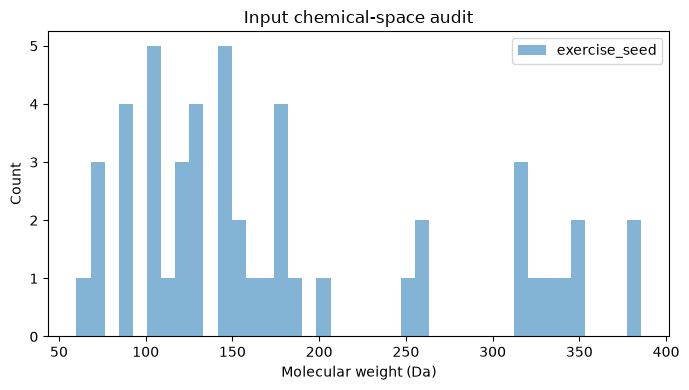

Unique exercise-seed structures: 49
Unique chemical-prior structures: 0


In [16]:
def descriptor_row(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {}
    return {
        "mw": Descriptors.MolWt(mol),
        "logp": Crippen.MolLogP(mol),
        "tpsa": rdMolDescriptors.CalcTPSA(mol),
        "hbd": Lipinski.NumHDonors(mol),
        "hba": Lipinski.NumHAcceptors(mol),
        "rotatable_bonds": Lipinski.NumRotatableBonds(mol),
        "heavy_atoms": mol.GetNumHeavyAtoms(),
        "formal_charge": Chem.GetFormalCharge(mol),
    }

desc = pd.DataFrame(valid["canonical_smiles"].apply(descriptor_row).tolist(),
                    index=valid.index)
valid = pd.concat([valid, desc], axis=1)
valid.to_csv(OUT_DIR / "standardized_molecule_manifest.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for role, grp in valid.groupby("data_role"):
    ax.hist(grp["mw"].dropna(), bins=40, alpha=0.55, label=role)
ax.set_xlabel("Molecular weight (Da)")
ax.set_ylabel("Count")
ax.set_title("Input chemical-space audit")
ax.legend()
plt.tight_layout()
plt.show()

print("Unique exercise-seed structures:",
      valid.loc[valid.data_role == "exercise_seed", "canonical_smiles"].nunique())
print("Unique chemical-prior structures:",
      valid.loc[valid.data_role == "chemical_prior", "canonical_smiles"].nunique())

## 6. Build a scaffold-aware split for evaluation

A random split can overstate generalization when close analogues appear in both training and test sets. This notebook assigns Bemis–Murcko scaffolds to splits where possible. Acyclic molecules have an empty Murcko scaffold and can collapse into one group; for those molecules, use a canonical-SMILES hash as a fallback group. The split is for evaluating reconstruction generalization, not for validating biological exercise response.

In [17]:
def scaffold_key(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return "INVALID"
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles = Chem.MolToSmiles(scaffold, canonical=True)
    if scaffold_smiles:
        return "scaffold:" + scaffold_smiles
    return "acyclic:" + hashlib.sha256(smiles.encode()).hexdigest()[:16]

model_df = valid[["canonical_smiles", "data_role", "source_type"]].drop_duplicates(
    "canonical_smiles"
).reset_index(drop=True)
model_df["scaffold_group"] = model_df["canonical_smiles"].map(scaffold_key)

groups = model_df["scaffold_group"].drop_duplicates().to_numpy()
rng = np.random.default_rng(SEED)
rng.shuffle(groups)
n = len(groups)
train_cut, val_cut = int(0.80*n), int(0.90*n)
train_groups = set(groups[:train_cut])
val_groups = set(groups[train_cut:val_cut])
test_groups = set(groups[val_cut:])

model_df["split"] = model_df["scaffold_group"].map(
    lambda g: "train" if g in train_groups else ("validation" if g in val_groups else "test")
)
display(model_df.groupby(["split", "data_role"]).size().rename("n").reset_index())
print("Scaffold groups:", model_df["scaffold_group"].nunique())
print("Note: with very few scaffold groups, metrics will be unstable; increase the dataset.")

,split,data_role,n
0,test,exercise_seed,6
1,train,exercise_seed,39
2,validation,exercise_seed,4


Scaffold groups: 44
Note: with very few scaffold groups, metrics will be unstable; increase the dataset.


## 7. Character vocabulary and denoising pairs

The model receives a randomly corrupted SMILES string and predicts its original canonical SMILES. Corruptions include token masking and token deletion; the clean target remains the same molecule. This is a self-supervised denoising objective. It is not paired biological translation and does not imply that a generated structure preserves the seed's activity.

In [18]:
PAD, BOS, EOS, UNK, MASK = "<pad>", "<bos>", "<eos>", "<unk>", "<mask>"
SPECIAL = [PAD, BOS, EOS, UNK, MASK]
smiles_all = model_df["canonical_smiles"].tolist()
alphabet = sorted(set("".join(smiles_all)))
itos = SPECIAL + alphabet
stoi = {tok: i for i, tok in enumerate(itos)}
PAD_ID, BOS_ID, EOS_ID, UNK_ID, MASK_ID = [stoi[t] for t in SPECIAL]

MAX_LEN = min(180, max(80, int(np.percentile([len(s) for s in smiles_all], 99)) + 8))
print("Vocabulary size:", len(itos), "| Max sequence length:", MAX_LEN)

def encode_smiles(s, add_bos=True, add_eos=True):
    ids = [stoi.get(ch, UNK_ID) for ch in s[:MAX_LEN-2]]
    if add_bos:
        ids = [BOS_ID] + ids
    if add_eos:
        ids = ids + [EOS_ID]
    return ids[:MAX_LEN]

def corrupt_smiles(s, mask_prob=0.12, delete_prob=0.04):
    out = []
    for ch in s:
        u = random.random()
        if u < delete_prob:
            continue
        if u < delete_prob + mask_prob:
            out.append(MASK)
        else:
            out.append(ch)
    if not out:
        out = [MASK]
    return "".join(out)

class DenoisingSmilesDataset(Dataset):
    def __init__(self, frame, training=False):
        self.smiles = frame["canonical_smiles"].tolist()
        self.training = training
    def __len__(self):
        return len(self.smiles)
    def __getitem__(self, idx):
        target = self.smiles[idx]
        source = corrupt_smiles(target) if self.training else target
        src = encode_smiles(source)
        tgt = encode_smiles(target)
        return src, tgt

def collate_batch(batch):
    srcs, tgts = zip(*batch)
    def pad(seqs):
        width = min(MAX_LEN, max(map(len, seqs)))
        arr = torch.full((len(seqs), width), PAD_ID, dtype=torch.long)
        for i, seq in enumerate(seqs):
            arr[i, :min(width, len(seq))] = torch.tensor(seq[:width])
        return arr
    return pad(srcs), pad(tgts)

train_frame = model_df[model_df.split == "train"].reset_index(drop=True)
val_frame = model_df[model_df.split == "validation"].reset_index(drop=True)
test_frame = model_df[model_df.split == "test"].reset_index(drop=True)

if len(train_frame) < 20:
    warnings.warn("Fewer than 20 training structures: model training is only a smoke test, not a publishable result.")

BATCH_SIZE = 64
train_loader = DataLoader(DenoisingSmilesDataset(train_frame, training=True),
                          batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(DenoisingSmilesDataset(val_frame, training=False),
                        batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(DenoisingSmilesDataset(test_frame, training=False),
                         batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

Vocabulary size: 24 | Max sequence length: 80


## 8. Define a compact encoder–decoder Transformer

This character-level model is intentionally transparent and relatively small. It is a baseline architecture; for serious work, compare against a pretrained chemical language model, a SMILES/SELFIES model, and simple analogue-generation baselines. Record all hyperparameters and compare models on the same held-out scaffold groups.

In [19]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

class SmilesDenoisingTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, layers=3, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos = PositionalEncoding(d_model, MAX_LEN, dropout)
        self.transformer = nn.Transformer(
            d_model=d_model, nhead=nhead,
            num_encoder_layers=layers, num_decoder_layers=layers,
            dim_feedforward=4*d_model, dropout=dropout, batch_first=True
        )
        self.out = nn.Linear(d_model, vocab_size)
    def forward(self, src, tgt_in):
        src_pad = src.eq(PAD_ID)
        tgt_pad = tgt_in.eq(PAD_ID)
        t = tgt_in.size(1)
        causal_mask = torch.triu(torch.ones(t, t, device=tgt_in.device, dtype=torch.bool), diagonal=1)
        src_emb = self.pos(self.emb(src) * np.sqrt(self.d_model))
        tgt_emb = self.pos(self.emb(tgt_in) * np.sqrt(self.d_model))
        h = self.transformer(src_emb, tgt_emb, tgt_mask=causal_mask,
                             src_key_padding_mask=src_pad,
                             tgt_key_padding_mask=tgt_pad,
                             memory_key_padding_mask=src_pad)
        return self.out(h)

model = SmilesDenoisingTransformer(len(itos)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 1,395,224


## 9. Train with early stopping and saved configuration

For a final study, run multiple random seeds, tune hyperparameters on validation scaffolds only, and reserve the test split for one final evaluation. This compact reference implementation trains one seed for demonstration.

/Users/dgomez/miniforge3/envs/exerkinemap/lib/python3.14/site-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


epoch 01 | train=3.4068 | val=2.7260
epoch 02 | train=2.6762 | val=2.5949
epoch 03 | train=2.4574 | val=2.4869
epoch 04 | train=2.3255 | val=2.4325
epoch 05 | train=2.2534 | val=2.3730
epoch 06 | train=2.2031 | val=2.3010
epoch 07 | train=2.1218 | val=2.2365
epoch 08 | train=2.0612 | val=2.1603
epoch 09 | train=1.9739 | val=2.0985
epoch 10 | train=1.8827 | val=2.0430
epoch 11 | train=1.7926 | val=1.9978
epoch 12 | train=1.7403 | val=1.9613
epoch 13 | train=1.6748 | val=1.9253
epoch 14 | train=1.6358 | val=1.8880
epoch 15 | train=1.5692 | val=1.8648
epoch 16 | train=1.5087 | val=1.8302
epoch 17 | train=1.4776 | val=1.7909
epoch 18 | train=1.4262 | val=1.7583
epoch 19 | train=1.3914 | val=1.7304
epoch 20 | train=1.3658 | val=1.7100
epoch 21 | train=1.3128 | val=1.6978
epoch 22 | train=1.2938 | val=1.6975
epoch 23 | train=1.2604 | val=1.6934
epoch 24 | train=1.2231 | val=1.6841
epoch 25 | train=1.2106 | val=1.6775


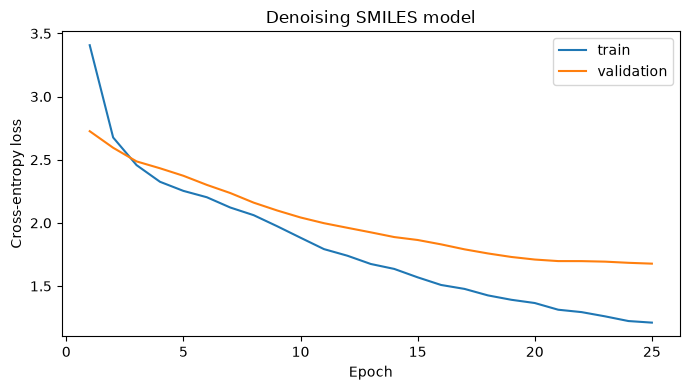

In [20]:
def epoch_pass(loader, training):
    model.train(training)
    losses = []
    for src, tgt in loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
        with torch.set_grad_enabled(training):
            logits = model(src, tgt_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses)) if losses else float("nan")

EPOCHS = 25
PATIENCE = 4
best_val, best_epoch, bad_epochs = float("inf"), 0, 0
history = []
best_path = OUT_DIR / "best_smiles_denoising_transformer.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss = epoch_pass(train_loader, True)
    val_loss = epoch_pass(val_loader, False)
    history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss})
    print(f"epoch {epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f}")
    if np.isfinite(val_loss) and val_loss < best_val:
        best_val, best_epoch, bad_epochs = val_loss, epoch, 0
        torch.save(model.state_dict(), best_path)
    else:
        bad_epochs += 1
    if bad_epochs >= PATIENCE:
        print("Early stopping.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(OUT_DIR / "training_history.csv", index=False)
if best_path.exists():
    model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history_df.epoch, history_df.train_loss, label="train")
ax.plot(history_df.epoch, history_df.validation_loss, label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Denoising SMILES model")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Decode sequences and generate candidates from exercise-metabolite seeds

Autoregressive sampling uses temperature and top-k filtering. Candidates are canonicalized after generation. Because character-level SMILES generation can produce malformed strings, chemical validity is measured explicitly rather than assumed. For larger projects, consider SELFIES or a pretrained molecular generator and benchmark it against this baseline.

In [21]:
@torch.no_grad()
def sample_from_seed(seed_smiles, n_samples=20, temperature=0.9, top_k=20):
    model.eval()
    src_ids = encode_smiles(seed_smiles)
    src = torch.tensor([src_ids], dtype=torch.long, device=DEVICE)
    outputs = []
    for _ in range(n_samples):
        generated = [BOS_ID]
        for _step in range(MAX_LEN - 1):
            tgt = torch.tensor([generated], dtype=torch.long, device=DEVICE)
            logits = model(src, tgt)[0, -1] / max(temperature, 1e-4)
            logits[PAD_ID] = -float("inf")
            logits[BOS_ID] = -float("inf")
            if top_k and top_k < logits.numel():
                values, indices = torch.topk(logits, top_k)
                filtered = torch.full_like(logits, -float("inf"))
                filtered[indices] = values
                logits = filtered
            probs = torch.softmax(logits, dim=-1)
            next_id = int(torch.multinomial(probs, 1).item())
            if next_id == EOS_ID:
                break
            generated.append(next_id)
        chars = [itos[i] for i in generated[1:] if i not in (PAD_ID, EOS_ID, BOS_ID)]
        outputs.append("".join(chars))
    return outputs

exercise_seeds = (
    valid.loc[valid.data_role == "exercise_seed", "canonical_smiles"]
    .drop_duplicates().tolist()
)
if not exercise_seeds:
    raise ValueError("No valid exercise-metabolite seed structures remain after standardization.")

N_SEEDS = min(10, len(exercise_seeds))
CANDIDATES_PER_SEED = 30
generated_rows = []

for seed_i, seed in enumerate(exercise_seeds[:N_SEEDS]):
    for candidate_i, generated in enumerate(sample_from_seed(
        seed, n_samples=CANDIDATES_PER_SEED, temperature=0.9, top_k=20
    )):
        canonical, status = standardize_smiles(generated)
        generated_rows.append({
            "seed_smiles": seed,
            "seed_index": seed_i,
            "candidate_index": candidate_i,
            "generated_smiles_raw": generated,
            "canonical_smiles": canonical,
            "standardization_status": status,
            "model": "character_transformer_denoising",
            "seed_value": SEED,
        })

generated = pd.DataFrame(generated_rows)
generated.to_csv(OUT_DIR / "generated_candidates_raw.csv", index=False)
display(generated.head())

[23:49:01] SMILES Parse Error: extra close parentheses while parsing: CC/CCO)=C\CCCO
[23:49:01] SMILES Parse Error: check for mistakes around position 7:
[23:49:01] CC/CCO)=C\CCCO
[23:49:01] ~~~~~~^
[23:49:01] SMILES Parse Error: Failed parsing SMILES 'CC/CCO)=C\CCCO' for input: 'CC/CCO)=C\CCCO'
[23:49:01] SMILES Parse Error: extra open parentheses while parsing: CCCCCCCCC(C(-C(O
[23:49:01] SMILES Parse Error: check for mistakes around position 10:
[23:49:01] CCCCCCCCC(C(-C(O
[23:49:01] ~~~~~~~~~^
[23:49:01] SMILES Parse Error: extra open parentheses while parsing: CCCCCCCCC(C(-C(O
[23:49:01] SMILES Parse Error: check for mistakes around position 12:
[23:49:01] CCCCCCCCC(C(-C(O
[23:49:01] ~~~~~~~~~~~^
[23:49:01] SMILES Parse Error: extra open parentheses while parsing: CCCCCCCCC(C(-C(O
[23:49:01] SMILES Parse Error: check for mistakes around position 15:
[23:49:01] CCCCCCCCC(C(-C(O
[23:49:01] ~~~~~~~~~~~~~~^
[23:49:01] SMILES Parse Error: Failed parsing SMILES 'CCCCCCCCC(C(-C(O' for in

,seed_smiles,seed_index,candidate_index,generated_smiles_raw,canonical_smiles,standardization_status,model,seed_value
0,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,0,0,CC/CCO)=C\CCCO,NaN,parse_failed,character_transformer_denoising,20261018
1,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,0,1,CCCCCCCCC(C(-C(O,NaN,parse_failed,character_transformer_denoising,20261018
2,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,0,2,C/C/CCC(=O)CC(=O,NaN,parse_failed,character_transformer_denoising,20261018
3,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,0,3,CCCCCCCCCCC/CC/CC(C=CC(=O)/2,NaN,parse_failed,character_transformer_denoising,20261018
4,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,0,4,[CCCCCCS/C(=O)CC/)C(=O,NaN,parse_failed,character_transformer_denoising,20261018


## 11. Evaluate validity, uniqueness, novelty, and nearest-neighbour similarity

Definitions:
- **Validity:** fraction of generated strings that RDKit can parse and sanitize.
- **Uniqueness:** fraction of valid generated structures that are unique within the generated set.
- **Novelty:** fraction of valid candidates absent from the model's full training corpus.
- **Nearest-neighbour Tanimoto:** maximum Morgan-fingerprint similarity to an input molecule. High similarity can be useful for analogue exploration but also signals limited novelty.

These are structural metrics only. They do not establish exercise responsiveness, metabolite identity, receptor binding, toxicity, or efficacy. For publication, report confidence intervals across independent seeds and compare with baselines.

In [22]:
from rdkit.Chem import AllChem, DataStructs

train_smiles_set = set(model_df.loc[model_df.split == "train", "canonical_smiles"])
all_input_smiles = valid["canonical_smiles"].drop_duplicates().tolist()
input_mols = [Chem.MolFromSmiles(s) for s in all_input_smiles if Chem.MolFromSmiles(s)]
input_fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=2048) for m in input_mols]

def evaluate_candidate(smiles):
    if not isinstance(smiles, str) or not smiles:
        return {"valid": False, "novel_vs_train": False, "nearest_input_tanimoto": np.nan}
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return {"valid": False, "novel_vs_train": False, "nearest_input_tanimoto": np.nan}
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048)
    sims = DataStructs.BulkTanimotoSimilarity(fp, input_fps) if input_fps else []
    return {
        "valid": True,
        "novel_vs_train": smiles not in train_smiles_set,
        "nearest_input_tanimoto": max(sims) if sims else np.nan,
        "mw": Descriptors.MolWt(mol),
        "logp": Crippen.MolLogP(mol),
        "tpsa": rdMolDescriptors.CalcTPSA(mol),
        "heavy_atoms": mol.GetNumHeavyAtoms(),
    }

metrics = pd.DataFrame(generated["canonical_smiles"].apply(evaluate_candidate).tolist())
generated_eval = pd.concat([generated.reset_index(drop=True), metrics], axis=1)
valid_generated = generated_eval.loc[generated_eval.valid & generated_eval.canonical_smiles.notna()].copy()

n_total = len(generated_eval)
n_valid = len(valid_generated)
summary = {
    "n_generated": int(n_total),
    "n_valid": int(n_valid),
    "validity_rate": float(n_valid / n_total) if n_total else None,
    "unique_valid_structures": int(valid_generated.canonical_smiles.nunique()),
    "uniqueness_rate": float(valid_generated.canonical_smiles.nunique() / n_valid) if n_valid else None,
    "novelty_rate_vs_train": float(valid_generated.novel_vs_train.mean()) if n_valid else None,
    "seed": SEED,
    "best_epoch": int(best_epoch),
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(summary, indent=2))
generated_eval.to_csv(OUT_DIR / "generated_candidates_evaluated.csv", index=False)
with open(OUT_DIR / "evaluation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

{
  "n_generated": 300,
  "n_valid": 33,
  "validity_rate": 0.11,
  "unique_valid_structures": 25,
  "uniqueness_rate": 0.7575757575757576,
  "novelty_rate_vs_train": 0.7878787878787878,
  "seed": 20261018,
  "best_epoch": 25,
  "timestamp_utc": "2026-10-19T06:49:28.851479+00:00"
}


## 12. Filter candidates conservatively and inspect structures

The filters below are transparent *triage rules*, not universal drug-likeness laws. They only remove malformed molecules and optional extreme descriptor values. Do not optimize candidates toward Lipinski's rules by default if the target chemical space is endogenous metabolites, where many legitimate molecules violate drug-like heuristics.

In [23]:
if not valid_generated.empty:
    # Broad sanity bounds for manual review, not a pharmacological classifier.
    reviewed = valid_generated[
        valid_generated["heavy_atoms"].between(3, 80)
        & valid_generated["mw"].between(30, 1200)
        & valid_generated["canonical_smiles"].notna()
    ].copy()
    reviewed = reviewed.drop_duplicates("canonical_smiles")
    reviewed["review_status"] = "computational_candidate_only"
    reviewed.to_csv(OUT_DIR / "candidate_review_queue.csv", index=False)
    print("Candidates passed broad structural triage:", len(reviewed))
    display(reviewed[["seed_smiles", "canonical_smiles", "mw", "logp",
                      "tpsa", "nearest_input_tanimoto"]].head(20))
else:
    reviewed = pd.DataFrame()
    print("No valid generated molecules; inspect training data, vocabulary, and model convergence.")

Candidates passed broad structural triage: 24


,seed_smiles,canonical_smiles,mw,logp,tpsa,nearest_input_tanimoto
8,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,CC=O,44.053,0.2052,17.07,0.181818
17,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,CCCCCC=O,100.161,1.7656,17.07,0.407407
25,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,CCC(O)CCCCO,132.203,0.9199,40.46,0.269231
27,CCCCCC(O)C(O)C/C=C\CCCCCCCC(=O)O,CCC=C=CCCC/C=C\COCCC=O,222.328,3.4398,26.30,0.244444
55,NC(=O)c1ncn([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)c1N,CC(O)O,62.068,-0.6830,40.46,0.416667
58,NC(=O)c1ncn([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)c1N,NC(O)O,63.056,-1.7867,66.48,0.294118
61,CC(CN)C(=O)O,NC=O,45.041,-0.8985,43.09,0.142857
62,CC(CN)C(=O)O,NCC=O,59.068,-0.8560,43.09,0.266667
69,CC(CN)C(=O)O,CC(=O)O,60.052,0.0909,37.30,1.000000
70,CC(CN)C(=O)O,NCCCC(=O)O,103.121,-0.1901,63.32,1.000000


## 13. Save model card, data manifest, and checksums

A reproducible report must preserve exact input file checksums and provenance. Do not publish compound records if their source license or data-use terms prohibit redistribution.

In [25]:
def sha256_file(path):
    if not path.exists():
        return None
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

config = {
    "project": "EXERKINEMAP exerkine-metabolite SMILES generation",
    "method": "character-level denoising encoder-decoder Transformer",
    "objective": "reconstruct canonical SMILES from corrupted SMILES",
    "seed": SEED,
    "device": str(DEVICE),
    "max_len": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val) if np.isfinite(best_val) else None,
    "vocab_size": len(itos),
    "input_files": {
        "exercise_metabolites_csv": {
            "path": str(EXERCISE_CSV),
            "sha256": sha256_file(EXERCISE_CSV),
        },
        "zinc_smiles_csv": {
            "path": str(ZINC_CSV),
            "sha256": sha256_file(ZINC_CSV),
        },
    },
    "limitations": [
        "ZINC is a chemical-space prior, not proof of metabolite or exerkine status.",
        "Generated candidates are computational hypotheses only.",
        "No bioactivity, exercise-response, safety, or clinical endpoint is predicted.",
        "Small data sets and one training seed are not sufficient for publication claims.",
        "SMILES validity does not establish synthetic accessibility or biological relevance.",
    ],
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
}
with open(OUT_DIR / "run_config_and_model_card.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved outputs to:", OUT_DIR.resolve())
print("\n".join(sorted(p.name for p in OUT_DIR.iterdir() if p.is_file())))

Saved outputs to: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/results/smiles_generation
best_smiles_denoising_transformer.pt
candidate_review_queue.csv
evaluation_summary.json
generated_candidates_evaluated.csv
generated_candidates_raw.csv
run_config_and_model_card.json
standardized_molecule_manifest.csv
training_history.csv


## 14. Publication checklist

Before describing these outputs as publishable evidence:

1. **Curate biological labels.** Include study DOI/accession, compound identifiers (preferably InChIKey), analytical platform, species, tissue, exercise protocol, sampling time, direction/effect size, adjusted p-value, and evidence tier.
2. **Resolve compound identity.** Match HMDB / PubChem / ChEBI identifiers and stereochemistry; distinguish isomers, adducts, salts, and unresolved metabolomics features.
3. **Keep ZINC separate.** Record ZINC release/download date, source URL, licensing, filters, and use it as unlabeled chemical prior only.
4. **Prevent leakage.** Split by scaffold and, where possible, by study/source; never allow the same standardized molecule across train/test.
5. **Benchmark.** Compare against random sampling, nearest-neighbour analogues, SELFIES or a pretrained molecular model, and an appropriate chemistry baseline.
6. **Quantify uncertainty.** Repeat across seeds, bootstrap confidence intervals, report failed generations, and include all filtering criteria.
7. **Validate independently.** Use external chemistry checks and experimentally measured endpoints. A generated SMILES is not an identified metabolite.
8. **Reproduce.** Pin package versions; archive input manifests, code commit, random seeds, configuration, and checksums.
9. **Report limitations.** This baseline learns SMILES syntax and local chemical patterns; it does not know whether a candidate is secreted during exercise or mediates an exerkine pathway.

In [26]:
import warnings
from pathlib import Path
import pandas as pd

# 1. Path definitions
EXERCISE_CSV = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv")

# 2. Helper functions
def read_csv_required(path: Path, label: str, required_cols=("smiles",)):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {label}: {path}\n"
            f"Provide a traceable CSV with columns {list(required_cols)}. "
            "No synthetic or placeholder dataset is created by this notebook."
        )
    df = pd.read_csv(path)
    missing = set(required_cols) - set(df.columns)
    if missing:
        raise ValueError(f"{label} is missing required columns: {sorted(missing)}")
    return df

In [32]:
exercise_raw = read_csv_required(
    EXERCISE_CSV, "exercise-metabolite input", required_cols=("smiles",)
)
exercise_raw["data_role"] = "exercise_seed"
exercise_raw["source_type"] = "exercise_metabolomics"

if ZINC_CSV.exists():
    zinc_raw = read_csv_required(ZINC_CSV, "ZINC input", required_cols=("smiles",))
    zinc_raw["data_role"] = "chemical_prior"
    zinc_raw["source_type"] = "ZINC"
    raw = pd.concat([exercise_raw, zinc_raw], ignore_index=True, sort=False)
else:
    warnings.warn(f"{ZINC_CSV} not found; training on exercise seeds only.")
    raw = exercise_raw.copy()

for col in ["compound_name", "source", "species", "study_id",
            "exercise_response", "response_direction", "zinc_id"]:
    if col not in raw.columns:
        raw[col] = pd.NA

print("Exercise input rows:", len(exercise_raw))
print("ZINC prior rows:", len(raw) - len(exercise_raw))
display(raw.head())

import pandas as pd, numpy as np, json, textwrap, os, sys, importlib.util
from pathlib import Path

# Build a clean metabolite input table from previous CSV, excluding broad classes, ambiguous compounds, and duplicate aliases
src = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exercise_metabolites.csv")
df = pd.read_csv(src).fillna("")
# Select unique entries with usable smiles and non-duplicate status
keep = df[df["smiles"].astype(str).str.strip().ne("")].copy()
keep = keep[~keep["identity_status"].astype(str).str.contains("duplicate_alias", case=False)]
# exclude provisional / tentative / unresolved identity until curated
keep = keep[~keep["identity_status"].astype(str).str.contains("provisional|tentative", case=False)]
# For rows with same canonical-ish name and smiles, dedup by normalized name
keep = keep.drop_duplicates(subset=["normalized_name", "smiles"])
# create fields for downstream code, avoiding exerkine_seed literal entirely
out_df = pd.DataFrame({
    "metabolite_id": [f"EXM{i:04d}" for i in range(1, len(keep)+1)],
    "metabolite_name": keep["normalized_name"].astype(str).values,
    "smiles": keep["smiles"].astype(str).values,
    "source_type": ["exercise_metabolomics_candidate"] * len(keep),
    "evidence_status": ["candidate_requires_literature_validation"] * len(keep),
    "reference_url": keep["reference_url"].astype(str).values,
    "curation_notes": keep["curation_notes"].astype(str).values,
})
out_csv = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exerkine_metabolites_named.csv")
out_df.to_csv(out_csv, index=False)

Exercise input rows: 65
ZINC prior rows: 0


/var/folders/g5/drz7gxc52xdftvrqcvh_9k5r0000gr/T/ipykernel_83608/3063099882.py:13: UserWarning: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/data/raw/exerkine_metabolites/zinc_smiles.csv not found; training on exercise seeds only.
  warnings.warn(f"{ZINC_CSV} not found; training on exercise seeds only.")


,input_label,normalized_name,smiles,identity_status,curation_notes,reference_url,data_role,source_type,compound_name,source,species,study_id,exercise_response,response_direction,zinc_id
0,"12,13-diHOME","12,13-DiHOME (12,13-dihydroxy-9Z-octadecenoic ...",CCCCCC(C(C/C=C\CCCCCCCC(=O)O)O)O,single_compound; provisional structure,PubChem CID 10236635; hydroxyl stereochemistry...,https://pubchem.ncbi.nlm.nih.gov/compound/1023...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,AICAR,AICAR / acadesine vs ZMP,C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O...,ambiguous_identity,"AICAR commonly means acadesine (AICAr, ribosid...",https://pubchem.ncbi.nlm.nih.gov/#query=AICAR,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,BAIBA,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,single_compound; stereochemistry unspecified,BAIBA has stereoisomers; this SMILES does not ...,https://pubchem.ncbi.nlm.nih.gov/#query=beta-a...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,2-OHB,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(C(=O)O)O,single_compound; stereochemistry unspecified,Also called alpha-hydroxybutyrate; stereochemi...,https://pubchem.ncbi.nlm.nih.gov/#query=2-hydr...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,3-OH,3-hydroxybutyric acid / 3-hydroxybutyrate,CC(CC(=O)O)O,tentative_identity,Interpreted as 3-hydroxybutyrate (beta-hydroxy...,https://pubchem.ncbi.nlm.nih.gov/#query=3-hydr...,exercise_seed,exercise_metabolomics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [35]:
import nbformat as nbf
nb = nbf.v4.new_notebook()
cells = []

In [43]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors
from sklearn.metrics import pairwise_distances

try:
    import umap
except ImportError as exc:
    raise ImportError("Install UMAP with: pip install umap-learn") from exc

RANDOM_STATE = 42
INPUT_CSV = Path("/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exerkine_metabolites_named.csv")
OUTPUT_DIR = Path("results/exerkine_metabolite_umap")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Input CSV:", INPUT_CSV.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Working directory: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks
Input CSV: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exerkine_metabolites_named.csv
Output directory: /Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/results/exerkine_metabolite_umap


In [44]:
INPUT_CSV

PosixPath('/Users/dgomez/MacWorkspace/Notebooks/JupyterNotebook/exerkinemap/notebooks/exerkine_metabolites_named.csv')

In [45]:
if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Missing {INPUT_CSV.resolve()}\\n"
        "Copy the provided exerkine_metabolites_named.csv into this path."
    )

raw = pd.read_csv(INPUT_CSV)
required = {"metabolite_name", "smiles"}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Input CSV missing columns: {sorted(missing)}")

raw["metabolite_name"] = raw["metabolite_name"].astype(str).str.strip()
raw["smiles"] = raw["smiles"].astype(str).str.strip()
raw = raw[(raw["metabolite_name"] != "") & (raw["smiles"] != "")].copy()

# One row per unique compound name + structure.
raw = raw.drop_duplicates(subset=["metabolite_name", "smiles"]).reset_index(drop=True)
print(f"Input rows with names and structures: {len(raw)}")
display(raw[["metabolite_id", "metabolite_name", "smiles", "evidence_status"]].head(20))

Input rows with names and structures: 46


,metabolite_id,metabolite_name,smiles,evidence_status
0,EXM0001,AICAR / acadesine vs ZMP,C1=NC(=C(N1[C@H]2[C@@H]([C@@H]([C@H](O2)CO)O)O...,candidate_requires_literature_validation
1,EXM0002,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,candidate_requires_literature_validation
2,EXM0003,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(C(=O)O)O,candidate_requires_literature_validation
3,EXM0004,Glycine,NCC(=O)O,candidate_requires_literature_validation
4,EXM0005,Alanine,CC(N)C(=O)O,candidate_requires_literature_validation
5,EXM0006,Valine,CC(C)C(N)C(=O)O,candidate_requires_literature_validation
6,EXM0007,Leucine,CC(C)CC(N)C(=O)O,candidate_requires_literature_validation
7,EXM0008,Isoleucine,CCC(C)C(N)C(=O)O,candidate_requires_literature_validation
8,EXM0009,Methionine,CSCCC(N)C(=O)O,candidate_requires_literature_validation
9,EXM0010,Proline,O=C(O)C1CCCN1,candidate_requires_literature_validation


In [46]:
molecules, valid_rows, invalid_rows = [], [], []

for idx, row in raw.iterrows():
    mol = Chem.MolFromSmiles(row["smiles"])
    if mol is None:
        invalid_rows.append({**row.to_dict(), "validation_issue": "RDKit could not parse SMILES"})
        continue
    canonical = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    molecules.append(mol)
    valid_rows.append({
        **row.to_dict(),
        "canonical_smiles": canonical,
        "molecular_weight": Descriptors.MolWt(mol),
        "logp": Descriptors.MolLogP(mol),
        "tpsa": rdMolDescriptors.CalcTPSA(mol),
        "hbd": rdMolDescriptors.CalcNumHBD(mol),
        "hba": rdMolDescriptors.CalcNumHBA(mol),
        "rotatable_bonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "heavy_atoms": mol.GetNumHeavyAtoms(),
    })

valid = pd.DataFrame(valid_rows)
if invalid_rows:
    pd.DataFrame(invalid_rows).to_csv(OUTPUT_DIR / "invalid_smiles_audit.csv", index=False)

if len(valid) < 4:
    raise ValueError(
        f"Only {len(valid)} valid molecules. UMAP needs more valid structures; "
        "check the input SMILES and provide additional curated compounds."
    )

fingerprints = [
    AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
    for mol in molecules
]
fp_array = np.zeros((len(fingerprints), 2048), dtype=np.uint8)
for i, fp in enumerate(fingerprints):
    DataStructs.ConvertToNumpyArray(fp, fp_array[i])

print(f"Valid structures: {len(valid)} / {len(raw)}")
display(valid[["metabolite_name", "canonical_smiles", "molecular_weight", "logp"]].head(20))

Valid structures: 46 / 46


,metabolite_name,canonical_smiles,molecular_weight,logp
0,AICAR / acadesine vs ZMP,NC(=O)c1ncn([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)c1N,258.234,-2.82430
1,beta-aminoisobutyric acid (BAIBA),CC(CN)C(=O)O,103.121,-0.33420
2,2-hydroxybutyric acid / 2-hydroxybutyrate,CCC(O)C(=O)O,104.105,-0.15810
3,Glycine,NCC(=O)O,75.067,-0.97030
4,Alanine,CC(N)C(=O)O,89.094,-0.58180
5,Valine,CC(C)C(N)C(=O)O,117.148,0.05430
6,Leucine,CC(C)CC(N)C(=O)O,131.175,0.44440
7,Isoleucine,CCC(C)C(N)C(=O)O,131.175,0.44440
8,Methionine,CSCCC(N)C(=O)O,149.215,0.15140
9,Proline,O=C(O)C1CCCN1,115.132,-0.17700
